In [9]:
from zipfile import ZipFile

import keras
import matplotlib.pyplot as plt
import numpy as np
from keras import layers
from keras.applications import MobileNet, ResNet50, VGG16
from keras.applications.mobilenet import preprocess_input as mobilenet_input
from keras.applications.resnet50 import preprocess_input as resnet_input
from keras.applications.vgg16 import preprocess_input as vgg_input
from numpy.lib.stride_tricks import sliding_window_view
from PIL import Image
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

In [10]:
# Question 1
seed = 42
rng = np.random.default_rng(seed)
keras.utils.set_random_seed(seed)

matrix = rng.integers(-3, 4, size=(3, 3))
kernel = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]])
padded = np.pad(matrix, 1)
windows = sliding_window_view(padded, kernel.shape)
convolution = np.sum(windows * kernel[::-1, ::-1], axis=(-2, -1))

relu = np.maximum(convolution, 0)
sigmoid = 1 / (1 + np.exp(-convolution))
pooling_windows = sliding_window_view(relu, (2, 2))
max_pooled = pooling_windows.max(axis=(-2, -1))
min_pooled = pooling_windows.min(axis=(-2, -1))
global_average = relu.mean()

flattened = relu.ravel()
dense = flattened @ rng.normal(size=(flattened.size, 2)) + np.array([0.5, -0.5])
batch = np.stack((dense, dense + 1, dense + 2))
normalized = (batch - batch.mean(axis=0)) / np.sqrt(batch.var(axis=0) + 1e-5)
keep_probability = 0.5
dropout = normalized * (rng.random(normalized.shape) < keep_probability) / keep_probability


def early_stopping():
    return keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    )


results = {
    "Matrix": matrix,
    "Padding (1 pixel)": padded,
    "Convolution": convolution,
    "ReLU": relu,
    "Sigmoid": sigmoid,
    "Max pooling": max_pooled,
    "Min pooling": min_pooled,
    "Global average pooling": global_average,
    "Flatten": flattened,
    "Dense": dense,
    "Batch normalization": normalized,
    "Dropout": dropout,
}
for title, values in results.items():
    print(f"{title}:\n{np.round(values, 3)}")

Matrix:
[[-3  2  1]
 [ 0  0  3]
 [-3  1 -2]]
Padding (1 pixel):
[[ 0  0  0  0  0]
 [ 0 -3  2  1  0]
 [ 0  0  0  3  0]
 [ 0 -3  1 -2  0]
 [ 0  0  0  0  0]]
Convolution:
[[ 14 -10   1]
 [ -6   6 -13]
 [ 13  -9  12]]
ReLU:
[[14  0  1]
 [ 0  6  0]
 [13  0 12]]
Sigmoid:
[[1.    0.    0.731]
 [0.002 0.998 0.   ]
 [1.    0.    1.   ]]
Max pooling:
[[14  6]
 [13 12]]
Min pooling:
[[0 0]
 [0 0]]
Global average pooling:
5.111
Flatten:
[14  0  1  0  6  0 13  0 12]
Dense:
[-32.457  31.065]
Batch normalization:
[[-1.225 -1.225]
 [-0.     0.   ]
 [ 1.225  1.225]]
Dropout:
[[-0.    -0.   ]
 [-0.     0.   ]
 [ 2.449  2.449]]


Classes: goldfish, Egyptian cat, banana
Image array: (600, 64, 64, 3)
Train / validation / test: 420 / 90 / 90
Lowest validation loss at epoch 24 of 25


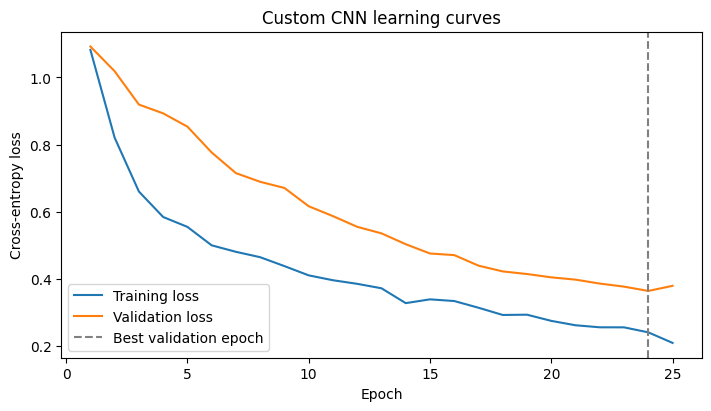

In [11]:
# Question 2
dataset_url = "https://cs231n.stanford.edu/tiny-imagenet-200.zip"
dataset_path = keras.utils.get_file(
    "tiny-imagenet-200.zip",
    origin=dataset_url,
    file_hash="90528d7ca1a48142e341f4ef8d21d0de",
    hash_algorithm="md5",
    cache_subdir="datasets",
)

classes = {
    "n01443537": "goldfish",
    "n02124075": "Egyptian cat",
    "n07753592": "banana",
}
images = []
labels = []
train_indices, val_indices, test_indices = [], [], []
split_rng = np.random.default_rng(seed)

with ZipFile(dataset_path) as archive:
    members = archive.namelist()
    for label, class_id in enumerate(classes):
        prefix = f"tiny-imagenet-200/train/{class_id}/images/"
        filenames = sorted(name for name in members if name.startswith(prefix) and name.endswith(".JPEG"))
        selected = split_rng.choice(filenames, size=200, replace=False)

        indices = np.arange(len(images), len(images) + len(selected))
        train_indices.extend(indices[:140])
        val_indices.extend(indices[140:170])
        test_indices.extend(indices[170:])
        for filename in selected:
            with archive.open(filename) as source, Image.open(source) as photo:
                images.append(np.asarray(photo.convert("RGB")))
            labels.append(label)

images = np.stack(images)
labels = np.array(labels)
train_indices = split_rng.permutation(train_indices)
val_indices = split_rng.permutation(val_indices)
test_indices = split_rng.permutation(test_indices)
print(f"Classes: {', '.join(classes.values())}")
print(f"Image array: {images.shape}")
print(f"Train / validation / test: {len(train_indices)} / {len(val_indices)} / {len(test_indices)}")


def fit_model(model, data, epochs):
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model.fit(
        data[train_indices], labels[train_indices],
        validation_data=(data[val_indices], labels[val_indices]),
        epochs=epochs, batch_size=32, callbacks=[early_stopping()], verbose=0,
    )


inputs = keras.Input(shape=(64, 64, 3))
x = layers.Rescaling(1 / 255)(inputs)
x = layers.Conv2D(16, 3, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)
maximum = layers.MaxPooling2D()(x)
minimum = -layers.MaxPooling2D()(-x)
x = layers.Concatenate()([maximum, minimum])
x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
x = layers.MaxPooling2D()(x)
average = layers.GlobalAveragePooling2D()(x)
flat = layers.Flatten()(layers.AveragePooling2D(pool_size=4)(x))
x = layers.Concatenate()([flat, average])
x = layers.Dense(48, activation="sigmoid")(x)
x = layers.Dropout(0.25)(x)
outputs = layers.Dense(len(classes), activation="softmax")(x)

custom_cnn = keras.Model(inputs, outputs)
history = fit_model(custom_cnn, images, epochs=25)
training_loss = history.history["loss"]
validation_loss = history.history["val_loss"]
best_epoch = np.argmin(validation_loss) + 1
print(f"Lowest validation loss at epoch {best_epoch} of {len(training_loss)}")

epochs = np.arange(1, len(training_loss) + 1)
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.plot(epochs, training_loss, label="Training loss")
ax.plot(epochs, validation_loss, label="Validation loss")
ax.axvline(best_epoch, color="gray", linestyle="--", label="Best validation epoch")
ax.set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Custom CNN learning curves")
ax.legend()
plt.show()

In [12]:
# Question 3
def test_metrics(model, data):
    actual = labels[test_indices]
    predicted = model(data[test_indices], training=False).numpy().argmax(axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        actual, predicted, labels=np.arange(len(classes)), average="macro", zero_division=0
    )
    return accuracy_score(actual, predicted), precision, recall, f1


scores = {"Custom CNN": test_metrics(custom_cnn, images)}
backbones = (
    ("VGG16", VGG16, vgg_input, 64),
    ("MobileNet", MobileNet, mobilenet_input, 128),
    ("ResNet50", ResNet50, resnet_input, 64),
)

for name, build, preprocess, size in backbones:
    backbone = build(weights="imagenet", include_top=False, input_shape=(size, size, 3), pooling="avg")
    backbone.trainable = False
    batches = []
    for start in range(0, len(images), 32):
        batch = images[start:start + 32].astype(np.float32)
        if size != 64:
            batch = layers.Resizing(size, size)(batch).numpy()
        batches.append(backbone(preprocess(batch), training=False).numpy())
    features = np.concatenate(batches)

    classifier = keras.Sequential([
        keras.Input(shape=(features.shape[1],)),
        layers.Dense(len(classes), activation="softmax"),
    ])
    fit_model(classifier, features, epochs=18)
    scores[name] = test_metrics(classifier, features)

print(f"{'Model':<12} {'Accuracy':>9} {'Precision':>9} {'Recall':>9} {'F1':>9}")
for name, (accuracy, precision, recall, f1) in scores.items():
    print(f"{name:<12} {accuracy:>9.3f} {precision:>9.3f} {recall:>9.3f} {f1:>9.3f}")

Model         Accuracy Precision    Recall        F1
Custom CNN       0.833     0.847     0.833     0.835
VGG16            0.878     0.881     0.878     0.878
MobileNet        0.978     0.979     0.978     0.978
ResNet50         0.933     0.935     0.933     0.932
